# Análisis: réplica de la variante 1 y ResNet50 con RadImageNet

Tres cosas con los resultados nuevos:

1. **Ruido de entrenamiento.** La variante `6clases_con_exclusion` se entrenó **dos veces** con la misma receta:
   - **Corrida A**: pipeline original (`dataset_final`, resolución original, ~35 h de GPU en total).
   - **Corrida B**: `dataset_final_224` (imágenes ya reducidas a 224×224; mismos píxeles de entrada, ~8 h).
   Ninguna de las dos tiene semilla fija. La diferencia entre A y B, modelo por modelo, mide cuánto varía un
   resultado de una corrida a otra (supuesto: el cambio de pipeline no altera los píxeles que ve el modelo, verificado antes;
   el entorno de Colab también pudo cambiar entre corridas, y A no lo registró).
2. **Estabilidad de las conclusiones** del análisis de las 4 variantes frente a ese ruido (ranking, efecto de la
   exclusión de calidad, efecto de quitar STB).
3. **ResNet50 con pesos de RadImageNet** frente a ResNet50 con pesos de ImageNet.

Todos los modelos de una misma variante comparten el mismo test set en el mismo orden, así que se puede comparar imagen a imagen.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2, kendalltau, spearmanr, wilcoxon

RESULTS_DIR = Path("../resultados/resultados_entrenamiento")
OUTPUT_DIR = Path("../resultados/comparacion_replicas")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RNG_SEED, N_BOOT = 42, 2000

RUN_A = RESULTS_DIR / "6_clases_con_exclusion"            # corrida A: pipeline lento
RUN_B = RESULTS_DIR / "6_clases_con_exclusion_224"        # corrida B: dataset_final_224
RAD = RESULTS_DIR / "resnet50_radimagenet"
OTHER = {"5clases_con_exclusion": RESULTS_DIR / "5_clases_con_exclusion",
         "6clases_sin_excluir": RESULTS_DIR / "6_clases_sin_exclusion",
         "5clases_sin_excluir": RESULTS_DIR / "5_clases_sin_exclusion"}

NICE = {"vgg16_bn": "VGG16", "mobilenetv3_small_100": "MobileNetV3", "resnet50": "ResNet50", "efficientnet_b0": "EfficientNetB0",
        "swin_tiny_patch4_window7_224": "Swin-Tiny", "vit_base_patch16_224": "ViT-Base", "deit_base_patch16_224": "DeiT-Base",
        "coatnet_0_rw_224": "CoAtNet", "maxvit_tiny_tf_224": "MaxViT", "custom_cnn_transformer": "Custom",
        "resnet50_radimagenet": "ResNet50-RadImageNet"}
FAMILIA = {"VGG16": "CNN", "ResNet50": "CNN", "MobileNetV3": "CNN", "EfficientNetB0": "CNN", "ResNet50-RadImageNet": "CNN",
           "ViT-Base": "Transformer", "DeiT-Base": "Transformer", "Swin-Tiny": "Transformer",
           "CoAtNet": "Híbrido", "MaxViT": "Híbrido", "Custom": "Custom"}
FAM_COLOR = {"CNN": "#3E63AE", "Transformer": "#3DA66B", "Híbrido": "#E8803A", "Custom": "#7B5EA7"}
CLASSES_6 = ["COVID-19", "Normal", "Pneumonia", "Silicosis", "STB", "Tuberculosis"]
K = len(CLASSES_6)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.grid": True, "grid.alpha": .25})

def save_fig(name):
    plt.savefig(OUTPUT_DIR / f"{name}.png", dpi=600, bbox_inches="tight")
    plt.savefig(OUTPUT_DIR / f"{name}.pdf", bbox_inches="tight")

def load_run(folder, with_preds=True):
    """{etiqueta: {'json': ..., 'y_true','y_pred','y_prob'}}. El modelo se identifica por el CONTENIDO del json
    (las carpetas tienen erratas como 'swiin')."""
    out = {}
    for f in sorted(folder.rglob("*__*.json")):
        if f.name.endswith("_metricas_por_clase.json"):
            continue
        d = json.load(open(f, encoding="utf-8"))
        if "history" not in d:
            continue
        label = NICE.get(d["model_name"], d["model_name"])
        rec = {"json": d}
        if with_preds:
            npz = np.load(f.with_name(f.stem + "_predicciones.npz"))
            rec.update(y_true=npz["y_true"], y_pred=npz["y_pred"], y_prob=npz["y_prob"])
        if label in out:
            print("AVISO: modelo duplicado en", folder.name, label)
        out[label] = rec
    return out

A, B, R = load_run(RUN_A), load_run(RUN_B), load_run(RAD)
print(f"A: {len(A)} modelos | B: {len(B)} modelos | RadImageNet: {list(R)}")
ref = A["ViT-Base"]["y_true"]
for nm, run in (("A", A), ("B", B), ("RadImageNet", R)):
    assert all(np.array_equal(ref, r["y_true"]) for r in run.values()), nm
print(f"Mismo test set (n={len(ref)}) en A, B y RadImageNet.")
assert set(A) == set(B) and len(A) == 10

# ---- métricas rápidas
def f1_per_class(y, p):
    cm = np.bincount(y * K + p, minlength=K * K).reshape(K, K)
    tp, fp, fn = np.diag(cm), cm.sum(0) - np.diag(cm), cm.sum(1) - np.diag(cm)
    den = 2 * tp + fp + fn
    return np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0)

f1m = lambda y, p: float(f1_per_class(y, p).mean())

def boot_delta(y, pa, pb, n=N_BOOT, seed=RNG_SEED):
    """IC95 bootstrap pareado de F1macro(b) - F1macro(a) sobre el mismo test set."""
    rng = np.random.default_rng(seed)
    d = np.empty(n)
    for i in range(n):
        idx = rng.integers(0, len(y), len(y))
        d[i] = f1m(y[idx], pb[idx]) - f1m(y[idx], pa[idx])
    return np.percentile(d, [2.5, 97.5]), d

def mcnemar(y, pa, pb):
    ca, cb = pa == y, pb == y
    b, c = int((ca & ~cb).sum()), int((~ca & cb).sum())
    stat = (abs(b - c) - 1) ** 2 / (b + c) if b + c else 0.0
    return b, c, float(chi2.sf(stat, 1))

A: 10 modelos | B: 10 modelos | RadImageNet: ['ResNet50-RadImageNet']
Mismo test set (n=3457) en A, B y RadImageNet.


## 1. Corrida A frente a corrida B (variante 1, 10 modelos)

`dF1 = F1(B) − F1(A)`. No es un error de A o de B: son dos muestras del mismo proceso de entrenamiento.

In [2]:
rows = []
for m in A:
    a, b = A[m]["json"], B[m]["json"]
    rows.append({"modelo": m, "familia": FAMILIA[m],
                 "F1_A": a["metrics"]["f1_macro"], "F1_B": b["metrics"]["f1_macro"],
                 "acc_A": a["metrics"]["accuracy"], "acc_B": b["metrics"]["accuracy"],
                 "auc_A": a["metrics"]["auc_roc_macro"], "auc_B": b["metrics"]["auc_roc_macro"],
                 "min_A": a["total_training_time_s"] / 60, "min_B": b["total_training_time_s"] / 60,
                 "epocas_A": len(a["history"]["epoch_time_s"]), "epocas_B": len(b["history"]["epoch_time_s"])})
rep = pd.DataFrame(rows)
rep["dF1"] = rep.F1_B - rep.F1_A
rep["F1_media"] = (rep.F1_A + rep.F1_B) / 2
rep["speedup"] = rep.min_A / rep.min_B
rep = rep.sort_values("F1_media", ascending=False).reset_index(drop=True)
rep.to_csv(OUTPUT_DIR / "replica_A_vs_B.csv", index=False)
print(rep[["modelo", "F1_A", "F1_B", "dF1", "acc_A", "acc_B", "epocas_A", "epocas_B"]].round(4).to_string(index=False))
print(f"\nTiempo total de entrenamiento: A {rep.min_A.sum() / 60:.1f} h | B {rep.min_B.sum() / 60:.1f} h "
      f"(B es {rep.min_A.sum() / rep.min_B.sum():.1f}x más rápida)")

        modelo   F1_A   F1_B     dF1  acc_A  acc_B  epocas_A  epocas_B
       CoAtNet 0.7742 0.7678 -0.0064 0.8493 0.8536        20        20
      ViT-Base 0.7661 0.7649 -0.0012 0.8557 0.8559        20        20
     DeiT-Base 0.7630 0.7594 -0.0037 0.8557 0.8551        20        20
     Swin-Tiny 0.7567 0.7621  0.0053 0.8531 0.8531        20        20
         VGG16 0.7516 0.7451 -0.0065 0.8426 0.8412        20        19
        MaxViT 0.7408 0.7431  0.0022 0.8149 0.8201        20        20
   MobileNetV3 0.7294 0.7166 -0.0128 0.8146 0.8033        20        20
EfficientNetB0 0.6852 0.6897  0.0046 0.7611 0.7640        20        20
        Custom 0.6870 0.6589 -0.0282 0.7596 0.7373        23        24
      ResNet50 0.6618 0.6509 -0.0109 0.7345 0.7278        20        20

Tiempo total de entrenamiento: A 34.7 h | B 8.8 h (B es 4.0x más rápida)


## 2. Cuánto varía un entrenamiento de una corrida a otra

Si cada resultado es `verdadero + ruido` con desviación `σ`, la diferencia entre dos corridas tiene desviación `σ·√2`, así que
`σ ≈ √(media(dF1²) / 2)`. Se usa la raíz de la media de cuadrados (y no la desviación estándar) para **no restar** un posible
desplazamiento sistemático entre A y B. Con 10 modelos el intervalo de σ sale de una chi-cuadrado con 10 grados de libertad.

**Diferencia mínima detectable (DMD):** entre dos modelos de *una sola corrida*, una diferencia menor que `1.96·σ·√2` no se
distingue del ruido de entrenamiento. Entre promedios de *dos corridas*, `1.96·σ`.

In [3]:
d = rep.dF1.to_numpy()
sigma = float(np.sqrt(np.mean(d ** 2) / 2))
ss = float(np.sum(d ** 2))
lo, hi = np.sqrt(ss / (2 * chi2.ppf(0.975, len(d)))), np.sqrt(ss / (2 * chi2.ppf(0.025, len(d))))
dmd1, dmd2 = 1.96 * sigma * np.sqrt(2), 1.96 * sigma

# ruido por muestreo del test (bootstrap) para comparar: error estándar del F1 macro de cada modelo (corrida B)
rng = np.random.default_rng(RNG_SEED)
se_boot = []
for m in B:
    y, p = B[m]["y_true"], B[m]["y_pred"]
    v = [f1m(y[i], p[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(500))]
    se_boot.append(np.std(v))
print(f"Media de dF1 (B-A): {d.mean():+.4f} | Wilcoxon p = {wilcoxon(d).pvalue:.3f}  (¿hay desplazamiento sistemático entre pipelines/entornos?)")
print(f"|dF1|: media {np.abs(d).mean():.4f}, máximo {np.abs(d).max():.4f}  ({rep.modelo[np.abs(d).argmax()]})")
print(f"σ (ruido de entrenamiento por corrida) ≈ {sigma:.4f}   IC95 [{lo:.4f}, {hi:.4f}]")
print(f"DMD entre dos modelos de UNA corrida: {dmd1:.4f} | entre promedios de DOS corridas: {dmd2:.4f}")
print(f"Para comparar: error estándar por muestreo del test (bootstrap), mediana entre modelos: {np.median(se_boot):.4f}")
pd.DataFrame({"sigma": [sigma], "sigma_ic_inf": [lo], "sigma_ic_sup": [hi], "dmd_una_corrida": [dmd1], "dmd_promedio_2_corridas": [dmd2],
              "se_bootstrap_mediana": [np.median(se_boot)], "media_dF1": [d.mean()]}).to_csv(OUTPUT_DIR / "ruido_entrenamiento.csv", index=False)

Media de dF1 (B-A): -0.0058 | Wilcoxon p = 0.105  (¿hay desplazamiento sistemático entre pipelines/entornos?)
|dF1|: media 0.0082, máximo 0.0282  (Custom)
σ (ruido de entrenamiento por corrida) ≈ 0.0078   IC95 [0.0055, 0.0138]
DMD entre dos modelos de UNA corrida: 0.0217 | entre promedios de DOS corridas: 0.0154
Para comparar: error estándar por muestreo del test (bootstrap), mediana entre modelos: 0.0103


## 3. ¿Cambia el ranking? ¿Qué modelos se distinguen de verdad?

In [4]:
rk_a = rep.sort_values("F1_A", ascending=False).modelo.tolist()
rk_b = rep.sort_values("F1_B", ascending=False).modelo.tolist()
rk_m = rep.sort_values("F1_media", ascending=False).modelo.tolist()
rho, _ = spearmanr(rep.F1_A, rep.F1_B)
tau, _ = kendalltau(rep.F1_A, rep.F1_B)
print("Ranking A:", rk_a)
print("Ranking B:", rk_b)
print(f"Spearman {rho:.3f} | Kendall {tau:.3f} | mismos 4 primeros: {set(rk_a[:4]) == set(rk_b[:4])} | "
      f"mismo orden completo: {rk_a == rk_b}")
print("Posiciones que cambian:", {m: (rk_a.index(m) + 1, rk_b.index(m) + 1) for m in rk_a if rk_a.index(m) != rk_b.index(m)})

# ¿qué pares se distinguen? (promedio de 2 corridas; DMD de promedios)
order = rep.modelo.tolist()
M = np.array([[rep.F1_media[i] - rep.F1_media[j] for j in range(len(order))] for i in range(len(order))])
sig = np.abs(M) >= dmd2
n_pairs = len(order) * (len(order) - 1) // 2
print(f"\nPares de modelos distinguibles por encima del ruido (|dif. de medias| >= {dmd2:.3f}): {int(sig.sum() // 2)} de {n_pairs}")
print("Empatados con ViT-Base (no distinguibles del ruido):", [m for m in order if m != "ViT-Base" and abs(rep.set_index('modelo').F1_media[m] - rep.set_index('modelo').F1_media['ViT-Base']) < dmd2])

Ranking A: ['CoAtNet', 'ViT-Base', 'DeiT-Base', 'Swin-Tiny', 'VGG16', 'MaxViT', 'MobileNetV3', 'Custom', 'EfficientNetB0', 'ResNet50']
Ranking B: ['CoAtNet', 'ViT-Base', 'Swin-Tiny', 'DeiT-Base', 'VGG16', 'MaxViT', 'MobileNetV3', 'EfficientNetB0', 'Custom', 'ResNet50']
Spearman 0.976 | Kendall 0.911 | mismos 4 primeros: True | mismo orden completo: False
Posiciones que cambian: {'DeiT-Base': (3, 4), 'Swin-Tiny': (4, 3), 'Custom': (8, 9), 'EfficientNetB0': (9, 8)}

Pares de modelos distinguibles por encima del ruido (|dif. de medias| >= 0.015): 35 de 45
Empatados con ViT-Base (no distinguibles del ruido): ['CoAtNet', 'DeiT-Base', 'Swin-Tiny']


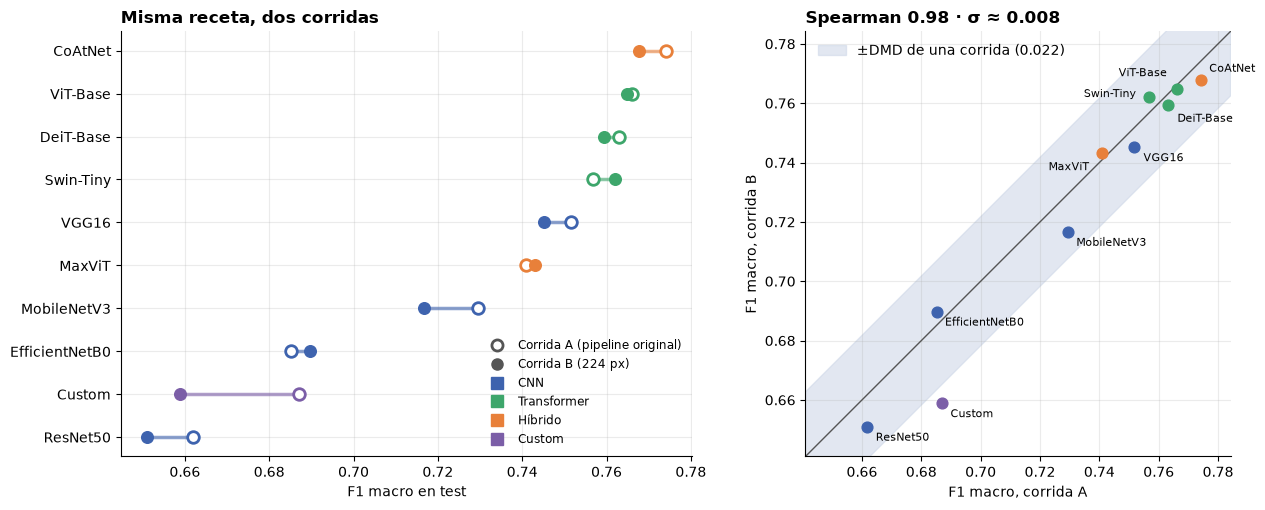

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axs[0]
y = np.arange(len(rep))[::-1]
for i, r in rep.iterrows():
    c = FAM_COLOR[r.familia]
    ax.plot([r.F1_A, r.F1_B], [y[i]] * 2, color=c, lw=2.5, alpha=.6)
    ax.scatter(r.F1_A, y[i], s=70, facecolor="white", edgecolor=c, lw=2, zorder=3)
    ax.scatter(r.F1_B, y[i], s=70, color=c, zorder=3)
ax.set_yticks(y); ax.set_yticklabels(rep.modelo)
ax.set_xlabel("F1 macro en test"); ax.set_title("Misma receta, dos corridas", loc="left", fontweight="bold")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", ls="", mfc="white", mec="#555", mew=2, ms=8, label="Corrida A (pipeline original)"),
                   Line2D([], [], marker="o", ls="", color="#555", ms=8, label="Corrida B (224 px)")] +
                  [Line2D([], [], marker="s", ls="", color=c, ms=8, label=f) for f, c in FAM_COLOR.items()],
          frameon=False, loc="lower right", fontsize=8.5)
LBL = {"CoAtNet": (6, 6, "left"), "ViT-Base": (-7, 9, "right"), "Swin-Tiny": (-9, 0, "right"), "DeiT-Base": (7, -12, "left"),
       "VGG16": (7, -10, "left"), "MaxViT": (-9, -12, "right")}
ax = axs[1]
lim = [rep[["F1_A", "F1_B"]].min().min() - .01, rep[["F1_A", "F1_B"]].max().max() + .01]
xs = np.linspace(*lim, 50)
ax.fill_between(xs, xs - dmd1, xs + dmd1, color="#cfd8e8", alpha=.6, label=f"±DMD de una corrida ({dmd1:.3f})")
ax.plot(lim, lim, color="#555", lw=1)
for _, r in rep.iterrows():
    ax.scatter(r.F1_A, r.F1_B, color=FAM_COLOR[r.familia], s=60, zorder=3)
    dx, dy, ha = LBL.get(r.modelo, (6, -10, "left"))
    ax.annotate(r.modelo, (r.F1_A, r.F1_B), xytext=(dx, dy), textcoords="offset points", fontsize=8, ha=ha)
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
ax.set_xlabel("F1 macro, corrida A"); ax.set_ylabel("F1 macro, corrida B")
ax.set_title(f"Spearman {rho:.2f} · σ ≈ {sigma:.3f}", loc="left", fontweight="bold"); ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); save_fig("fig_replica_A_vs_B"); plt.show()

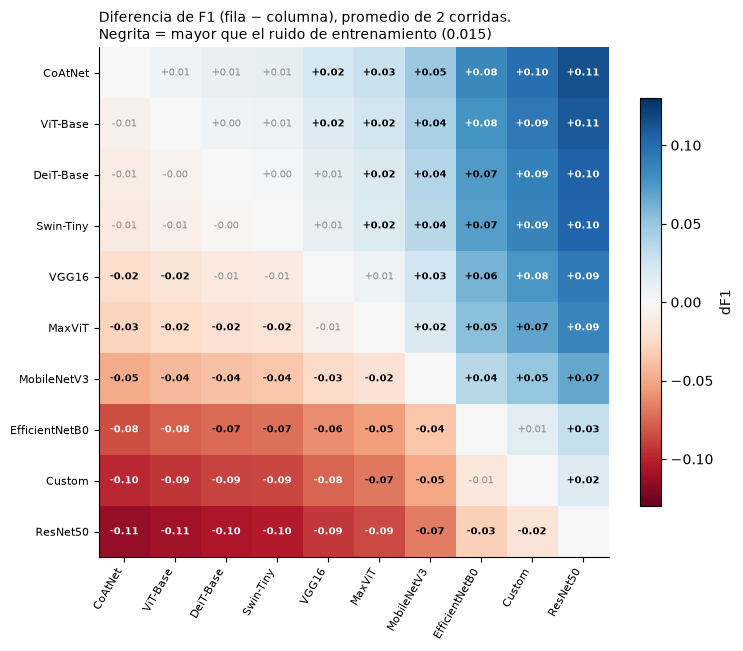

In [6]:
fig, ax = plt.subplots(figsize=(7.6, 6.4))
im = ax.imshow(M, cmap="RdBu", vmin=-.13, vmax=.13)
for i in range(len(order)):
    for j in range(len(order)):
        if i != j:
            ax.text(j, i, f"{M[i, j]:+.2f}", ha="center", va="center", fontsize=7.5,
                    color=("white" if abs(M[i, j]) > .075 else "black") if sig[i, j] else "#8a8a8a", fontweight="bold" if sig[i, j] else "normal")
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=8); ax.grid(False)
ax.set_title(f"Diferencia de F1 (fila − columna), promedio de 2 corridas.\nNegrita = mayor que el ruido de entrenamiento ({dmd2:.3f})", loc="left", fontsize=10)
plt.colorbar(im, shrink=.8, label="dF1"); plt.tight_layout(); save_fig("fig_distinguibilidad_modelos"); plt.show()

## 4. ¿Resisten las conclusiones del análisis de 4 variantes al ruido?

El efecto de **excluir las imágenes de calidad dudosa** (6 clases) y el de **quitar STB** (con exclusión) se calcularon con la corrida A
como variante 1. Aquí se repiten con la corrida B y con el promedio: si el signo o la conclusión cambian, dependían del ruido.
Las otras 3 variantes tienen una sola corrida.

In [7]:
OT = {v: load_run(p, with_preds=False) for v, p in OTHER.items()}
f1 = lambda run, m: run[m]["json"]["metrics"]["f1_macro"]
sin_excl, cinco = OT["6clases_sin_excluir"], OT["5clases_con_exclusion"]
ef = pd.DataFrame(index=list(A))
ef.index.name = "modelo"
# efecto de EXCLUIR calidad (6 clases) = F1(con exclusión) - F1(sin excluir); la variante 1 es la que tiene dos corridas
ef["calidad_A"] = [f1(A, m) - f1(sin_excl, m) for m in ef.index]
ef["calidad_B"] = [f1(B, m) - f1(sin_excl, m) for m in ef.index]
ef["calidad_media"] = [(f1(A, m) + f1(B, m)) / 2 - f1(sin_excl, m) for m in ef.index]
# efecto de QUITAR STB (con exclusión) = F1(5 clases) - F1(6 clases)
ef["stb_A"] = [f1(cinco, m) - f1(A, m) for m in ef.index]
ef["stb_B"] = [f1(cinco, m) - f1(B, m) for m in ef.index]
ef["stb_media"] = [f1(cinco, m) - (f1(A, m) + f1(B, m)) / 2 for m in ef.index]
ef.to_csv(OUTPUT_DIR / "efectos_con_ruido.csv")
print(ef.round(4).to_string())
print("\nEfecto de EXCLUIR calidad (F1 con exclusión − sin excluir), 10 modelos:")
for k in ("calidad_A", "calidad_B", "calidad_media"):
    v = ef[k]; print(f"  {k:<14} media {v.mean():+.4f} | positivos {int((v > 0).sum())}/10 | Wilcoxon p = {wilcoxon(v).pvalue:.3f}")
print("Efecto de QUITAR STB (F1 5 clases − 6 clases), 10 modelos:")
for k in ("stb_A", "stb_B", "stb_media"):
    v = ef[k]; print(f"  {k:<14} media {v.mean():+.4f} | positivos {int((v > 0).sum())}/10 | Wilcoxon p = {wilcoxon(v).pvalue:.3f}")

                calidad_A  calidad_B  calidad_media   stb_A   stb_B  stb_media
modelo                                                                        
CoAtNet            0.0130     0.0065         0.0097  0.0885  0.0950     0.0918
Custom             0.0114    -0.0168        -0.0027  0.0532  0.0814     0.0673
DeiT-Base         -0.0049    -0.0086        -0.0067  0.1052  0.1089     0.1070
EfficientNetB0    -0.0169    -0.0124        -0.0146  0.1084  0.1038     0.1061
MaxViT            -0.0071    -0.0049        -0.0060  0.0893  0.0871     0.0882
MobileNetV3       -0.0103    -0.0231        -0.0167  0.0781  0.0910     0.0845
ResNet50           0.0115     0.0006         0.0060  0.0626  0.0735     0.0680
Swin-Tiny         -0.0021     0.0032         0.0006  0.1018  0.0964     0.0991
VGG16              0.0051    -0.0014         0.0019  0.0979  0.1043     0.1011
ViT-Base           0.0028     0.0016         0.0022  0.1120  0.1132     0.1126

Efecto de EXCLUIR calidad (F1 con exclusión − sin e

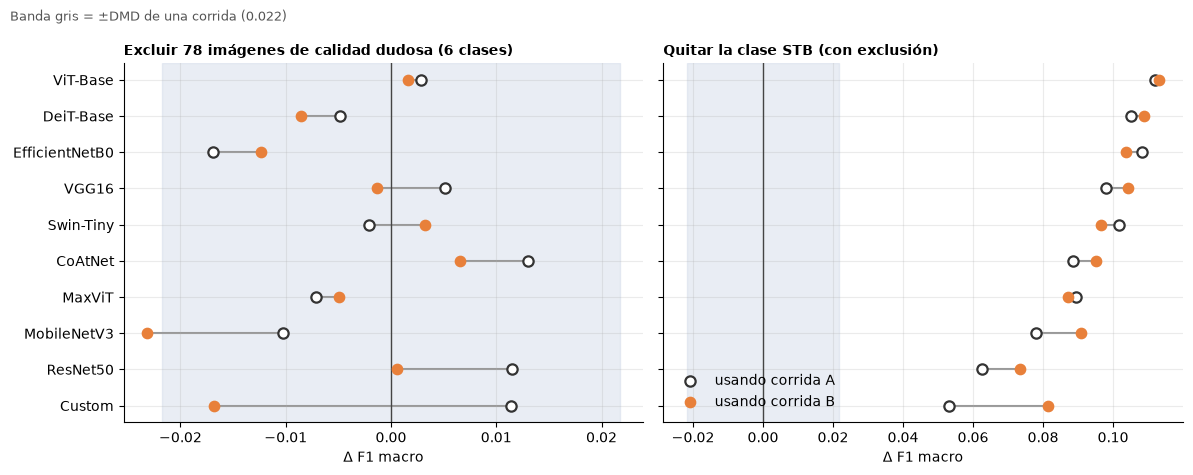

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
order_ef = ef.sort_values("stb_media").index.tolist()
yy = np.arange(len(order_ef))
for ax, (ka, kb, ttl) in zip(axs, (("calidad_A", "calidad_B", "Excluir 78 imágenes de calidad dudosa (6 clases)"),
                                   ("stb_A", "stb_B", "Quitar la clase STB (con exclusión)"))):
    for i, m in enumerate(order_ef):
        ax.plot([ef.loc[m, ka], ef.loc[m, kb]], [i, i], color="#999", lw=1.5, zorder=1)
        ax.scatter(ef.loc[m, ka], i, s=55, facecolor="white", edgecolor="#333", lw=1.6, zorder=3, label="usando corrida A" if i == 0 else None)
        ax.scatter(ef.loc[m, kb], i, s=55, color="#E8803A", zorder=3, label="usando corrida B" if i == 0 else None)
    ax.axvline(0, color="#444", lw=1); ax.axvspan(-dmd1, dmd1, color="#cfd8e8", alpha=.45, zorder=0)
    ax.set_title(ttl, loc="left", fontsize=10, fontweight="bold"); ax.set_xlabel("Δ F1 macro")
axs[0].set_yticks(yy); axs[0].set_yticklabels(order_ef); axs[1].legend(frameon=False, loc="lower left")
fig.suptitle(f"Banda gris = ±DMD de una corrida ({dmd1:.3f})", x=.01, ha="left", fontsize=9, color="#555")
plt.tight_layout(); save_fig("fig_efectos_con_ruido"); plt.show()

## 5. ResNet50 con RadImageNet frente a ResNet50 con ImageNet

Misma arquitectura, misma receta, mismos datos; solo cambia el origen de los pesos del backbone (RadImageNet usa su propio
preprocesamiento BGR / [-1,1]). ImageNet tiene **dos** corridas (A y B); RadImageNet, una. Se compara contra cada una con
bootstrap pareado (IC95 de ΔF1 macro) y McNemar, y se pone la diferencia en contexto con el ruido de la Sección 2.

In [9]:
rad = R["ResNet50-RadImageNet"]
rows = []
for tag, run in (("ImageNet A", A), ("ImageNet B", B)):
    pa, pb, y = run["ResNet50"]["y_pred"], rad["y_pred"], rad["y_true"]
    (lo_, hi_), _ = boot_delta(y, pa, pb)
    b_, c_, p_ = mcnemar(y, pa, pb)
    rows.append({"comparacion": f"RadImageNet − ResNet50 {tag}", "F1_imagenet": f1m(y, pa), "F1_radimagenet": f1m(y, pb),
                 "dF1": f1m(y, pb) - f1m(y, pa), "ic95_inf": lo_, "ic95_sup": hi_, "dF1_en_sigmas": (f1m(y, pb) - f1m(y, pa)) / sigma,
                 "acc_dif": float((pb == y).mean() - (pa == y).mean()), "mcnemar_b": b_, "mcnemar_c": c_, "mcnemar_p": p_})
rd = pd.DataFrame(rows)
rd.to_csv(OUTPUT_DIR / "radimagenet_vs_imagenet.csv", index=False)
print(rd.round(4).to_string(index=False))
y = rad["y_true"]
print(f"\nRuido de entrenamiento: σ ≈ {sigma:.4f}; el propio ResNet50 de ImageNet varió {abs(f1m(y, B['ResNet50']['y_pred']) - f1m(y, A['ResNet50']['y_pred'])):.4f} entre A y B.")
pos = lambda run: sorted(((f1m(y, r["y_pred"]), m) for m, r in run.items()), reverse=True)
print("Puesto de RadImageNet entre los 10 modelos (si sustituyera al ResNet50 ImageNet): A ->",
      1 + sum(v > f1m(y, rad['y_pred']) for v, m in pos(A) if m != "ResNet50"), "| B ->", 1 + sum(v > f1m(y, rad['y_pred']) for v, m in pos(B) if m != "ResNet50"))

                      comparacion  F1_imagenet  F1_radimagenet    dF1  ic95_inf  ic95_sup  dF1_en_sigmas  acc_dif  mcnemar_b  mcnemar_c  mcnemar_p
RadImageNet − ResNet50 ImageNet A       0.6618          0.6817 0.0199   -0.0030    0.0419         2.5372   0.0104        396        432     0.2239
RadImageNet − ResNet50 ImageNet B       0.6509          0.6817 0.0308    0.0087    0.0525         3.9281   0.0171        371        430     0.0404

Ruido de entrenamiento: σ ≈ 0.0078; el propio ResNet50 de ImageNet varió 0.0109 entre A y B.
Puesto de RadImageNet entre los 10 modelos (si sustituyera al ResNet50 ImageNet): A -> 10 | B -> 9


              ImageNet A  ImageNet B  RadImageNet  RadImageNet − media(ImageNet)
COVID-19           0.777       0.781        0.761                         -0.018
Normal             0.701       0.701        0.749                          0.047
Pneumonia          0.837       0.826        0.828                         -0.004
Silicosis          0.526       0.510        0.507                         -0.011
STB                0.468       0.449        0.541                          0.082
Tuberculosis       0.662       0.639        0.706                          0.055


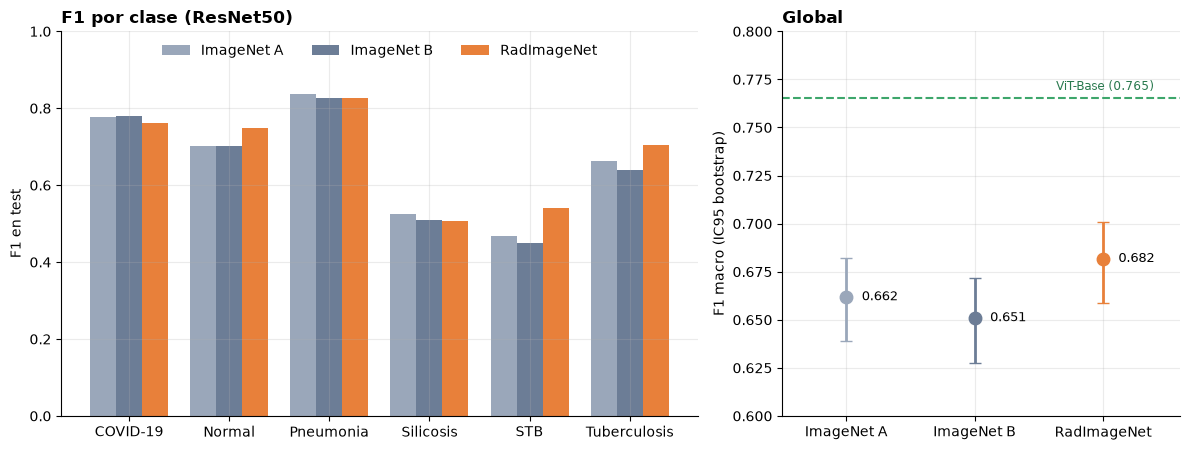

In [10]:
pc = {"ImageNet A": f1_per_class(y, A["ResNet50"]["y_pred"]), "ImageNet B": f1_per_class(y, B["ResNet50"]["y_pred"]), "RadImageNet": f1_per_class(y, rad["y_pred"])}
pcd = pd.DataFrame(pc, index=CLASSES_6)
pcd["RadImageNet − media(ImageNet)"] = pcd["RadImageNet"] - (pcd["ImageNet A"] + pcd["ImageNet B"]) / 2
pcd.to_csv(OUTPUT_DIR / "radimagenet_f1_por_clase.csv")
print(pcd.round(3).to_string())

def boot_f1(yv, pv, n=1000, seed=RNG_SEED):
    rg = np.random.default_rng(seed)
    v = [f1m(yv[i], pv[i]) for i in (rg.integers(0, len(yv), len(yv)) for _ in range(n))]
    return np.percentile(v, [2.5, 97.5])

fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axs[0]; w = .26; x = np.arange(K)
for j, (k, col) in enumerate((("ImageNet A", "#9aa7ba"), ("ImageNet B", "#6c7d96"), ("RadImageNet", "#E8803A"))):
    ax.bar(x + (j - 1) * w, pcd[k], w, color=col, label=k)
ax.set_xticks(x); ax.set_xticklabels(CLASSES_6); ax.set_ylabel("F1 en test"); ax.set_ylim(0, 1.0)
ax.set_title("F1 por clase (ResNet50)", loc="left", fontweight="bold")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.0))
ax = axs[1]
vals = [("ImageNet A", A["ResNet50"]["y_pred"], "#9aa7ba"), ("ImageNet B", B["ResNet50"]["y_pred"], "#6c7d96"), ("RadImageNet", rad["y_pred"], "#E8803A")]
vit_mean = rep.set_index("modelo").F1_media["ViT-Base"]
for i, (nm, pv, col) in enumerate(vals):
    f, (l_, h_) = f1m(y, pv), boot_f1(y, pv)
    ax.errorbar(i, f, yerr=[[f - l_], [h_ - f]], fmt="o", color=col, ms=9, capsize=4, lw=2)
    ax.text(i + .12, f, f"{f:.3f}", va="center", fontsize=9)
ax.axhline(vit_mean, color="#3DA66B", lw=1.5, ls="--")
ax.text(2.4, vit_mean + .004, f"ViT-Base ({vit_mean:.3f})", color="#2a7a4f", fontsize=8.5, ha="right")
ax.set_xticks(range(3)); ax.set_xticklabels([v[0] for v in vals]); ax.set_xlim(-.5, 2.6)
ax.set_ylim(.60, .80); ax.set_ylabel("F1 macro (IC95 bootstrap)"); ax.set_title("Global", loc="left", fontweight="bold")
plt.tight_layout(); save_fig("fig_radimagenet_vs_imagenet"); plt.show()

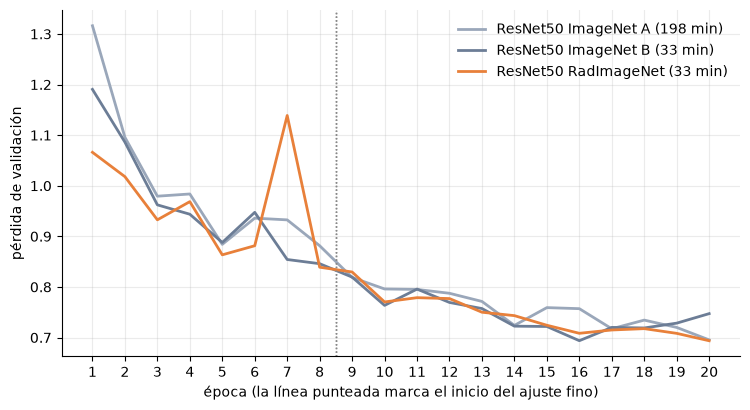

In [11]:
fig, ax = plt.subplots(figsize=(7.6, 4.2))
for tag, rec, col in (("ResNet50 ImageNet A", A["ResNet50"], "#9aa7ba"), ("ResNet50 ImageNet B", B["ResNet50"], "#6c7d96"), ("ResNet50 RadImageNet", rad, "#E8803A")):
    h = rec["json"]["history"]
    ax.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], color=col, lw=2, label=f"{tag} ({sum(h['epoch_time_s']) / 60:.0f} min)")
    p2 = next((i for i, ph in enumerate(h["phase"]) if "fase2" in ph), None)
    if p2 is not None:
        ax.axvline(p2 + .5, color="#888", ls=":", lw=1)
ax.set_xticks(range(1, 21)); ax.set_xlabel("época (la línea punteada marca el inicio del ajuste fino)"); ax.set_ylabel("pérdida de validación"); ax.legend(frameon=False)
plt.tight_layout(); save_fig("fig_curvas_resnet"); plt.show()

## 6. Entorno de ejecución y tiempos

La corrida B y RadImageNet usaron el `entrenamiento_utils.py` que registra las versiones; la corrida A y las otras 3 variantes no.

In [12]:
envs = {}
for tag, rec in (("Corrida B (224), ViT-Base", B["ViT-Base"]), ("RadImageNet", rad)):
    envs[tag] = rec["json"].get("entorno", {})
env = pd.DataFrame(envs)
env.to_csv(OUTPUT_DIR / "entorno_colab.csv")
print(env.to_string())
same_env = all(B[m]["json"].get("entorno") == B["ViT-Base"]["json"].get("entorno") for m in B)
print("\n¿Los 10 modelos de la corrida B comparten exactamente el mismo entorno?", same_env)
print(rep[["modelo", "min_A", "min_B", "speedup"]].round(1).to_string(index=False))

                         Corrida B (224), ViT-Base                           RadImageNet
python                                     3.13.15                               3.13.15
torch                                 2.11.0+cu130                          2.11.0+cu130
torchvision                           0.26.0+cu130                          0.26.0+cu130
timm                                        1.0.30                                1.0.30
numpy                                        2.1.3                                 2.1.3
scikit-learn                                 1.6.1                                 1.6.1
pandas                                       2.2.3                                 2.2.3
cuda                                          13.0                                  13.0
cudnn                                        92700                                 92700
gpu                                       Tesla T4                              Tesla T4
platform      Linux-6

## 7. Resumen

In [13]:
r1, r2 = rd.iloc[0], rd.iloc[1]
excl = lambda r: "excluye" if (r.ic95_inf > 0 or r.ic95_sup < 0) else "incluye"
lines = [
    f"RUIDO DE ENTRENAMIENTO. Entre las corridas A y B, |dF1| medio = {np.abs(d).mean():.4f} (máx. {np.abs(d).max():.4f}, {rep.modelo[np.abs(d).argmax()]}). "
    f"σ por corrida ≈ {sigma:.4f} (IC95 {lo:.4f} a {hi:.4f}); diferencia mínima detectable: {dmd1:.3f} entre dos modelos de una corrida y {dmd2:.3f} entre promedios de dos.",
    f"DESPLAZAMIENTO SISTEMÁTICO A→B: media {d.mean():+.4f}, Wilcoxon p = {wilcoxon(d).pvalue:.2f} "
    f"({'no se detecta' if wilcoxon(d).pvalue > .05 else 'SÍ se detecta'}).",
    f"RANKING. Spearman A-B = {rho:.2f}; mismos 4 primeros: {set(rk_a[:4]) == set(rk_b[:4])}; orden completo idéntico: {rk_a == rk_b}. "
    f"Pares distinguibles del ruido (promedio de 2 corridas): {int(sig.sum() // 2)} de {n_pairs}.",
    f"RADIMAGENET vs IMAGENET (ResNet50). F1: ImageNet A {r1.F1_imagenet:.3f} / B {r2.F1_imagenet:.3f} frente a RadImageNet {r1.F1_radimagenet:.3f}. "
    f"dF1 = {r1.dF1:+.3f} (IC95 {r1.ic95_inf:+.3f} a {r1.ic95_sup:+.3f}; el IC {excl(r1)} el 0) frente a A y {r2.dF1:+.3f} "
    f"(IC95 {r2.ic95_inf:+.3f} a {r2.ic95_sup:+.3f}; {excl(r2)} el 0) frente a B; equivale a {r1.dF1_en_sigmas:.1f} y {r2.dF1_en_sigmas:.1f} veces σ. "
    f"McNemar p = {r1.mcnemar_p:.3g} y {r2.mcnemar_p:.3g}.",
]
print("\n\n".join(lines))

RUIDO DE ENTRENAMIENTO. Entre las corridas A y B, |dF1| medio = 0.0082 (máx. 0.0282, Custom). σ por corrida ≈ 0.0078 (IC95 0.0055 a 0.0138); diferencia mínima detectable: 0.022 entre dos modelos de una corrida y 0.015 entre promedios de dos.

DESPLAZAMIENTO SISTEMÁTICO A→B: media -0.0058, Wilcoxon p = 0.11 (no se detecta).

RANKING. Spearman A-B = 0.98; mismos 4 primeros: True; orden completo idéntico: False. Pares distinguibles del ruido (promedio de 2 corridas): 35 de 45.

RADIMAGENET vs IMAGENET (ResNet50). F1: ImageNet A 0.662 / B 0.651 frente a RadImageNet 0.682. dF1 = +0.020 (IC95 -0.003 a +0.042; el IC incluye el 0) frente a A y +0.031 (IC95 +0.009 a +0.053; excluye el 0) frente a B; equivale a 2.5 y 3.9 veces σ. McNemar p = 0.224 y 0.0404.
